## Model 02: Logistic Regression (Predicting Employee Attrition)

**Author:** Tyra Nyambura  
**Date:** 19th, October 2026  
**Goal:** Master our second model by pivoting from predicting continuous prices to solving a **binary classification** problem.

### Welcome to Model 02!
After exploring Linear Regression, the next logical leap is understanding how to predict categorical outcomes. Today, we are analyzing the **IBM HR Analytics Dataset**, which tracks **14,999 employees across 10 corporate columns** with zero missing values. Our objective is to predict **Employee Attrition** (whether an employee stays or leaves the company).

### Why Can't We Use Linear Regression Here?
Linear Regression predicts a continuous range from negative infinity to positive infinity (-∞ to ∞). If we try to map a binary classification choice like `Left (1)` or `Stayed (0)` using a straight linear line, our predictions will fly past 1 and drop below 0, rendering our probabilities mathematically invalid. 

### Enter Logistic Regression & The Sigmoid Function
To fix this, Logistic Regression takes the standard linear model equation and wraps it tightly inside a **Sigmoid Activation Function** (σ). This squashes *any* real-numbered input down into a strict probability range between **0 and 1**.

The mathematical equation is:

\[P(Y=1\vert{}X) = \sigma(\beta_0 + \beta_1X_1 + \dots + \beta_nX_n) = \frac{1}{1 + e^{-(\beta_0 + \beta_1X_1 + \dots + \beta_nX_n)}}\]

Where:
* e is Euler's constant (~2.718)
* The output is the probability (0.0 to 1.0) of an employee leaving the company.
* If the probability is ≥ 0.5, we classify them as `1` (Left). Otherwise, they are classified as `0` (Stayed).

Let's load our toolkit and explore this dataset!

### Step 1: Loading our Toolkit
Classification requires an entirely different suite of mathematical metrics compared to regression. Instead of looking at distances from a line (like MAE or RMSE), we will load a **Confusion Matrix**, **Accuracy Score**, and a **Classification Report** (Precision, Recall, and F1-Score) to judge how well our probability boundary splits the classes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Classification modeling components
from sklearn.model_selection import train_test_split

# Visual configuration
plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

print("Classification tools loaded successfully!")

Classification tools loaded successfully!


### Step 2: Data Loading & Shape Verification
Let's pull the IBM HR Analytics dataset into our notebook. We want to confirm its structure: 14,999 rows, 10 columns, and verify that there are indeed no missing values as advertised.


In [2]:
# Load the IBM HR Analytics dataset
df = pd.read_csv("../../data/hr-analytics-job-prediction/HR_comma_sep.csv")

# Verify the metadata requirements (14,999 records, 10 columns, no missing values)
print("Dataset Verification")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Total Missing Values: {df.isnull().sum().sum()}")

print("\nFeatures and Data Types")
print(df.dtypes)

# Display the first 5 employees
df.head()

Dataset Verification
Shape: 14999 rows, 10 columns
Total Missing Values: 0

--- Features and Data Types ---
satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                object
salary                    object
dtype: object


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Step 3: Target Isolation & Class Imbalance Analysis

Before encoding our features, we need to locate our target variable. In the IBM HR dataset, this column is usually named `left` (where `1` means the employee quit, and `0` means they stayed).

In classification problems, we must check for **Class Imbalance**. If 95% of employees stay, a lazy model could guess `0` for every single person and claim 95% accuracy while completely failing to spot the people who leave. We need to see the exact split between the two classes.


Target Class Distribution
Class 0 (Stayed): 11428 employees (76.19%)
Class 1 (Left): 3571 employees (23.81%)


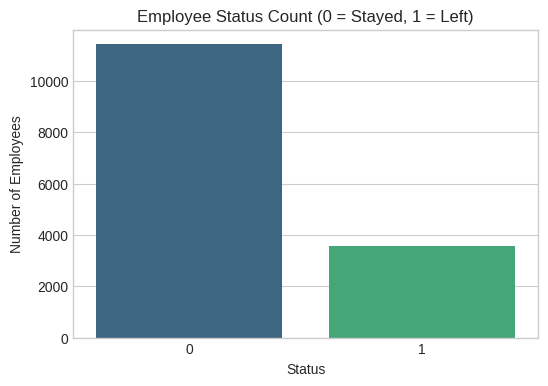

In [3]:
# Count the distribution of the target variable
attrition_counts = df["left"].value_counts()
attrition_percentages = df["left"].value_counts(normalize=True) * 100

print("Target Class Distribution")
for cls, count in attrition_counts.items():
    print(
        f"Class {cls} ({'Left' if cls == 1 else 'Stayed'}): {count} employees ({attrition_percentages[cls]:.2f}%)"
    )

# Visualize the distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="left", data=df, hue="left", palette="viridis", legend=False)
plt.title("Employee Status Count (0 = Stayed, 1 = Left)")
plt.xlabel("Status")
plt.ylabel("Number of Employees")
plt.show()

### Step 4: Transforming Categorical Features

Our dataset contains text columns like `Department` (sales, technical, HR, etc.) and `salary` (low, medium, high). Just like in our Linear Regression model, our Logistic Regression equation requires raw mathematical inputs to feed into the Sigmoid function.

We will use `pd.get_dummies` to transform these columns. Because `salary` has an inherent order (low < medium < high), an alternative would be ordinal encoding, but converting them into dummy variables with `drop_first=True` allows the model to calculate the distinct impact of jumping from a low salary to a high salary without breaking linear assumptions.


In [4]:
# Identify non-numeric categorical columns to dummy encode
categorical_cols = ["Department", "salary"]

# Apply One-Hot Encoding and drop the first category to avoid multicollinearity
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Turn the true/false boolean matrices into 1/0 integers
df_encoded = df_encoded.astype(int)

# Preview our clean, fully-numerical machine learning matrix
print(f"Encoded dataset dimensions: {df_encoded.shape}")
df_encoded.head()

Encoded dataset dimensions: (14999, 19)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department_RandD,Department_accounting,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical,salary_low,salary_medium
0,0,0,2,157,3,0,1,0,0,0,0,0,0,0,1,0,0,1,0
1,0,0,5,262,6,0,1,0,0,0,0,0,0,0,1,0,0,0,1
2,0,0,7,272,4,0,1,0,0,0,0,0,0,0,1,0,0,0,1
3,0,0,5,223,5,0,1,0,0,0,0,0,0,0,1,0,0,1,0
4,0,0,2,159,3,0,1,0,0,0,0,0,0,0,1,0,0,1,0


### Step 5: Data Splitting (Train vs. Test Matrix)

With our dataset entirely digitized, we now decouple our independent features ($X$) from our target column ($y = \text{left}$). 

We will apply an 80/20 train/test split. The model will optimize its coefficients using the 80% split, and we will hold out 20% to test whether its probability scores hold up accurately when evaluating an entirely new batch of employees.


In [5]:
# Isolate the target variable
y = df_encoded["left"]
X = df_encoded.drop(columns=["left"])

# Execute the 80/20 train-test split with a fixed random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data Split Dimensions")
print(f"X_train shape: {X_train.shape} rows | y_train shape: {y_train.shape} rows")
print(f"X_test shape:  {X_test.shape} rows | y_test shape:  {y_test.shape} rows")

Data Split Dimensions
X_train shape: (11999, 18) rows | y_train shape: (11999,) rows
X_test shape:  (3000, 18) rows | y_test shape:  (3000,) rows


### Step 6: Initializing and Training the Logistic Model

Unlike Linear Regression, which calculates its weights in one single analytical jump using the Normal Equation, Logistic Regression uses an iterative optimization routine. 

#### The Loss Function: Binary Cross-Entropy (Log-Loss)
Because our target values are strictly 0 and 1, we can't use squared errors. Instead, the algorithm relies on **Log-Loss**:

\[\text{Log-Loss} = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]\]

#### The Optimization: Gradient Descent
1. The engine makes an initial guess for the weights (\(\beta\)).
2. It calculates the Log-Loss cost. If an employee actually left (\(y=1\)) but the model predicted a 1% probability of leaving (\(\hat{y}=0.01\)), the log penalty approaches infinity.
3. The engine uses **Gradient Descent** to step down the error surface, iteratively refining the weights until it minimizes the overall cost function.


In [6]:
# Initialize the model with an increased iteration limit to guarantee convergence
log_model = LogisticRegression(max_iter=1000, random_state=42)

# Fit the model parameters using Gradient Descent optimization
log_model.fit(X_train, y_train)

print("Logistic Regression model converged! Probability boundary weights calculated successfully.")

Logistic Regression model converged! Probability boundary weights calculated successfully.


### Step 7: Classification Evaluation Metrics

To see how well our model scores new data, we pull predictions from `X_test`. In classification, basic accuracy can mask flaws. We must evaluate three deeper concepts:

1. **Confusion Matrix:** A \(2 \times 2\) grid tracking exactly where the model predicted correctly and where it blundered:
   * **True Positives (TP):** Predicted left, actually left.
   * **False Positives (FP):** Predicted left, actually stayed (**False Alarm**).
   * **True Negatives (TN):** Predicted stayed, actually stayed.
   * **False Negatives (FN):** Predicted stayed, actually left (**Missed Signal**).

2. **Precision:** Out of all employees the model *predicted* would leave, how many actually did? High precision means low false alarms.
3. **Recall (Sensitivity):** Out of all employees who *actually* left, how many did the model catch? High recall means few missed signals.
4. **F1-Score:** The harmonic mean balancing Precision and Recall into a single value.


In [7]:
# Generate binary classifications (0 or 1)
predictions = log_model.predict(X_test)

# Calculate performance metrics
accuracy = accuracy_score(y_test, predictions)
cm = confusion_matrix(y_test, predictions)

print(f"Overall Model Accuracy: {accuracy * 100:.2f}%\n")
print("Detailed Classification Report")
print(classification_report(y_test, predictions, target_names=["Stayed (0)", "Left (1)"]))

Overall Model Accuracy: 76.23%

Detailed Classification Report
              precision    recall  f1-score   support

  Stayed (0)       0.77      0.97      0.86      2294
    Left (1)       0.47      0.08      0.14       706

    accuracy                           0.76      3000
   macro avg       0.62      0.53      0.50      3000
weighted avg       0.70      0.76      0.69      3000



### Step 8: Visualizing the Confusion Matrix

To visually capture where the model is succeeding or failing, we map the raw confusion matrix array into a heatmap. This cleanly shows us whether our model's main weak point is false alarms (FP) or completely missing the employees who are planning to walk out the door (FN).


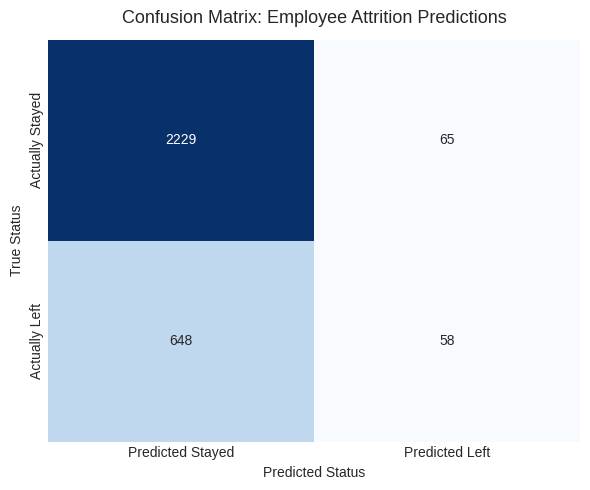

In [8]:
plt.figure(figsize=(6, 5), dpi=100)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Stayed", "Predicted Left"],
    yticklabels=["Actually Stayed", "Actually Left"],
)

plt.title("Confusion Matrix: Employee Attrition Predictions", fontsize=13, pad=12)
plt.ylabel("True Status")
plt.xlabel("Predicted Status")
plt.tight_layout()
plt.show()